In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_dict = pd.read_csv('../data/l&t_train.csv')

### ---------------------------------------------------

In [3]:
test = pd.read_csv('../data/l&t_test.csv')

In [4]:
test.columns

Index(['UniqueID', 'disbursed_amount', 'asset_cost', 'ltv', 'branch_id',
       'supplier_id', 'manufacturer_id', 'Current_pincode_ID', 'Date.of.Birth',
       'Employment.Type', 'DisbursalDate', 'State_ID', 'Employee_code_ID',
       'MobileNo_Avl_Flag', 'Aadhar_flag', 'PAN_flag', 'VoterID_flag',
       'Driving_flag', 'Passport_flag', 'PERFORM_CNS.SCORE',
       'PERFORM_CNS.SCORE.DESCRIPTION', 'PRI.NO.OF.ACCTS', 'PRI.ACTIVE.ACCTS',
       'PRI.OVERDUE.ACCTS', 'PRI.CURRENT.BALANCE', 'PRI.SANCTIONED.AMOUNT',
       'PRI.DISBURSED.AMOUNT', 'SEC.NO.OF.ACCTS', 'SEC.ACTIVE.ACCTS',
       'SEC.OVERDUE.ACCTS', 'SEC.CURRENT.BALANCE', 'SEC.SANCTIONED.AMOUNT',
       'SEC.DISBURSED.AMOUNT', 'PRIMARY.INSTAL.AMT', 'SEC.INSTAL.AMT',
       'NEW.ACCTS.IN.LAST.SIX.MONTHS', 'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS',
       'AVERAGE.ACCT.AGE', 'CREDIT.HISTORY.LENGTH', 'NO.OF_INQUIRIES'],
      dtype='str')

In [5]:
test['DisbursalDate'] = pd.to_datetime(test['DisbursalDate'], format='%d-%m-%y')

In [6]:
test['DisbursalDate'].agg(['min', 'max'])

min   2018-11-03
max   2018-11-30
Name: DisbursalDate, dtype: datetime64[us]

In [7]:
test['DisbursalDate'].dt.to_period('M').value_counts().sort_index()

DisbursalDate
2018-11    112392
Freq: M, Name: count, dtype: int64

### test file = Nov 2018, unlabelled → use for drift monitoring

## -----------------------------------------------------------------

In [8]:
df_dict

,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,Date.of.Birth,Employment.Type,...,SEC.SANCTIONED.AMOUNT,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,AVERAGE.ACCT.AGE,CREDIT.HISTORY.LENGTH,NO.OF_INQUIRIES,loan_default
0,420825,50578,58400,89.55,67,22807,45,1441,01-01-84,Salaried,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
1,537409,47145,65550,73.23,67,22807,45,1502,31-07-85,Self employed,...,0,0,1991,0,0,1,1yrs 11mon,1yrs 11mon,0,1
2,417566,53278,61360,89.63,67,22807,45,1497,24-08-85,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
3,624493,57513,66113,88.48,67,22807,45,1501,30-12-93,Self employed,...,0,0,31,0,0,0,0yrs 8mon,1yrs 3mon,1,1
4,539055,52378,60300,88.39,67,22807,45,1495,09-12-77,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233149,626432,63213,105405,60.72,34,20700,48,1050,01-08-88,Salaried,...,0,0,4084,0,0,0,1yrs 9mon,3yrs 3mon,0,0
233150,606141,73651,100600,74.95,34,23775,51,990,05-12-88,Self employed,...,0,0,1565,0,0,0,0yrs 6mon,0yrs 6mon,0,0
233151,613658,33484,71212,48.45,77,22186,86,2299,01-06-76,Salaried,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
233152,548084,34259,73286,49.10,77,22186,86,2299,26-03-94,Salaried,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0


In [9]:
df = pd.read_csv('../data/l&t_train.csv')

In [10]:
df.head()

,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,Date.of.Birth,Employment.Type,...,SEC.SANCTIONED.AMOUNT,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,AVERAGE.ACCT.AGE,CREDIT.HISTORY.LENGTH,NO.OF_INQUIRIES,loan_default
0,420825,50578,58400,89.55,67,22807,45,1441,01-01-84,Salaried,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
1,537409,47145,65550,73.23,67,22807,45,1502,31-07-85,Self employed,...,0,0,1991,0,0,1,1yrs 11mon,1yrs 11mon,0,1
2,417566,53278,61360,89.63,67,22807,45,1497,24-08-85,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
3,624493,57513,66113,88.48,67,22807,45,1501,30-12-93,Self employed,...,0,0,31,0,0,0,0yrs 8mon,1yrs 3mon,1,1
4,539055,52378,60300,88.39,67,22807,45,1495,09-12-77,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,1,1


In [11]:
df.shape

(233154, 41)

In [12]:
df.dtypes

UniqueID                                 int64
disbursed_amount                         int64
asset_cost                               int64
ltv                                    float64
branch_id                                int64
supplier_id                              int64
manufacturer_id                          int64
Current_pincode_ID                       int64
Date.of.Birth                              str
Employment.Type                            str
DisbursalDate                              str
State_ID                                 int64
Employee_code_ID                         int64
MobileNo_Avl_Flag                        int64
Aadhar_flag                              int64
PAN_flag                                 int64
VoterID_flag                             int64
Driving_flag                             int64
Passport_flag                            int64
PERFORM_CNS.SCORE                        int64
PERFORM_CNS.SCORE.DESCRIPTION              str
PRI.NO.OF.ACC

In [13]:
df.describe()

,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,State_ID,Employee_code_ID,...,SEC.OVERDUE.ACCTS,SEC.CURRENT.BALANCE,SEC.SANCTIONED.AMOUNT,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,NO.OF_INQUIRIES,loan_default
count,233154.000000,233154.000000,2.331540e+05,233154.000000,233154.000000,233154.000000,233154.000000,233154.000000,233154.000000,233154.000000,...,233154.000000,2.331540e+05,2.331540e+05,2.331540e+05,2.331540e+05,2.331540e+05,233154.000000,233154.000000,233154.000000,233154.000000
mean,535917.573376,54356.993528,7.586507e+04,74.746530,72.936094,19638.635035,69.028054,3396.880247,7.262243,1549.477148,...,0.007244,5.427793e+03,7.295923e+03,7.179998e+03,1.310548e+04,3.232684e+02,0.381833,0.097481,0.206615,0.217071
std,68315.693711,12971.314171,1.894478e+04,11.456636,69.834995,3491.949566,22.141304,2238.147502,4.482230,975.261278,...,0.111079,1.702370e+05,1.831560e+05,1.825925e+05,1.513679e+05,1.555369e+04,0.955107,0.384439,0.706498,0.412252
min,417428.000000,13320.000000,3.700000e+04,10.030000,1.000000,10524.000000,45.000000,1.000000,1.000000,1.000000,...,0.000000,-5.746470e+05,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
25%,476786.250000,47145.000000,6.571700e+04,68.880000,14.000000,16535.000000,48.000000,1511.000000,4.000000,713.000000,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
50%,535978.500000,53803.000000,7.094600e+04,76.800000,61.000000,20333.000000,86.000000,2970.000000,6.000000,1451.000000,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
75%,595039.750000,60413.000000,7.920175e+04,83.670000,130.000000,23000.000000,86.000000,5677.000000,10.000000,2362.000000,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.999000e+03,0.000000e+00,0.000000,0.000000,0.000000,0.000000
max,671084.000000,990572.000000,1.628992e+06,95.000000,261.000000,24803.000000,156.000000,7345.000000,22.000000,3795.000000,...,8.000000,3.603285e+07,3.000000e+07,3.000000e+07,2.564281e+07,4.170901e+06,35.000000,20.000000,36.000000,1.000000


In [14]:
df.isnull().sum()

UniqueID                                  0
disbursed_amount                          0
asset_cost                                0
ltv                                       0
branch_id                                 0
supplier_id                               0
manufacturer_id                           0
Current_pincode_ID                        0
Date.of.Birth                             0
Employment.Type                        7661
DisbursalDate                             0
State_ID                                  0
Employee_code_ID                          0
MobileNo_Avl_Flag                         0
Aadhar_flag                               0
PAN_flag                                  0
VoterID_flag                              0
Driving_flag                              0
Passport_flag                             0
PERFORM_CNS.SCORE                         0
PERFORM_CNS.SCORE.DESCRIPTION             0
PRI.NO.OF.ACCTS                           0
PRI.ACTIVE.ACCTS                

In [15]:
df['Employment.Type'].unique()

<ArrowStringArray>
['Salaried', 'Self employed', nan]
Length: 3, dtype: str

In [16]:
# can replace nan with 'other'

<Axes: xlabel='loan_default'>

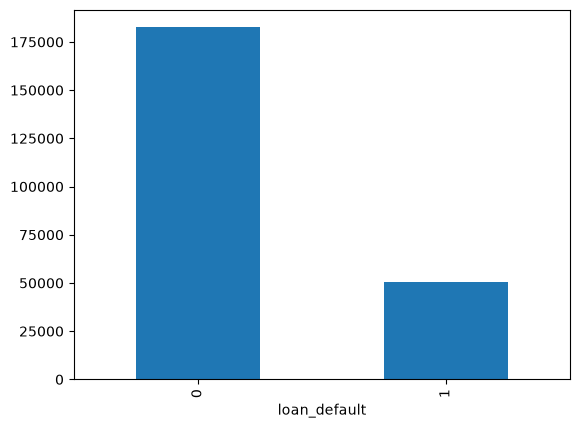

In [17]:
df['loan_default'].value_counts().plot(kind = 'bar')

In [18]:
df.columns

Index(['UniqueID', 'disbursed_amount', 'asset_cost', 'ltv', 'branch_id',
       'supplier_id', 'manufacturer_id', 'Current_pincode_ID', 'Date.of.Birth',
       'Employment.Type', 'DisbursalDate', 'State_ID', 'Employee_code_ID',
       'MobileNo_Avl_Flag', 'Aadhar_flag', 'PAN_flag', 'VoterID_flag',
       'Driving_flag', 'Passport_flag', 'PERFORM_CNS.SCORE',
       'PERFORM_CNS.SCORE.DESCRIPTION', 'PRI.NO.OF.ACCTS', 'PRI.ACTIVE.ACCTS',
       'PRI.OVERDUE.ACCTS', 'PRI.CURRENT.BALANCE', 'PRI.SANCTIONED.AMOUNT',
       'PRI.DISBURSED.AMOUNT', 'SEC.NO.OF.ACCTS', 'SEC.ACTIVE.ACCTS',
       'SEC.OVERDUE.ACCTS', 'SEC.CURRENT.BALANCE', 'SEC.SANCTIONED.AMOUNT',
       'SEC.DISBURSED.AMOUNT', 'PRIMARY.INSTAL.AMT', 'SEC.INSTAL.AMT',
       'NEW.ACCTS.IN.LAST.SIX.MONTHS', 'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS',
       'AVERAGE.ACCT.AGE', 'CREDIT.HISTORY.LENGTH', 'NO.OF_INQUIRIES',
       'loan_default'],
      dtype='str')

<Axes: xlabel='State_ID', ylabel='count'>

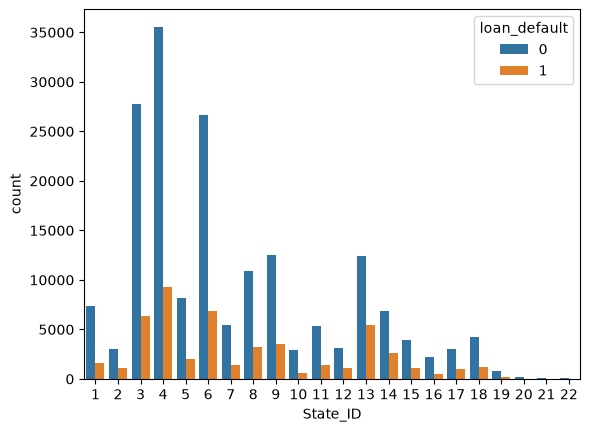

In [19]:
sns.countplot(data = df, x = 'State_ID', hue = 'loan_default')

In [20]:
# default rate (%) by state

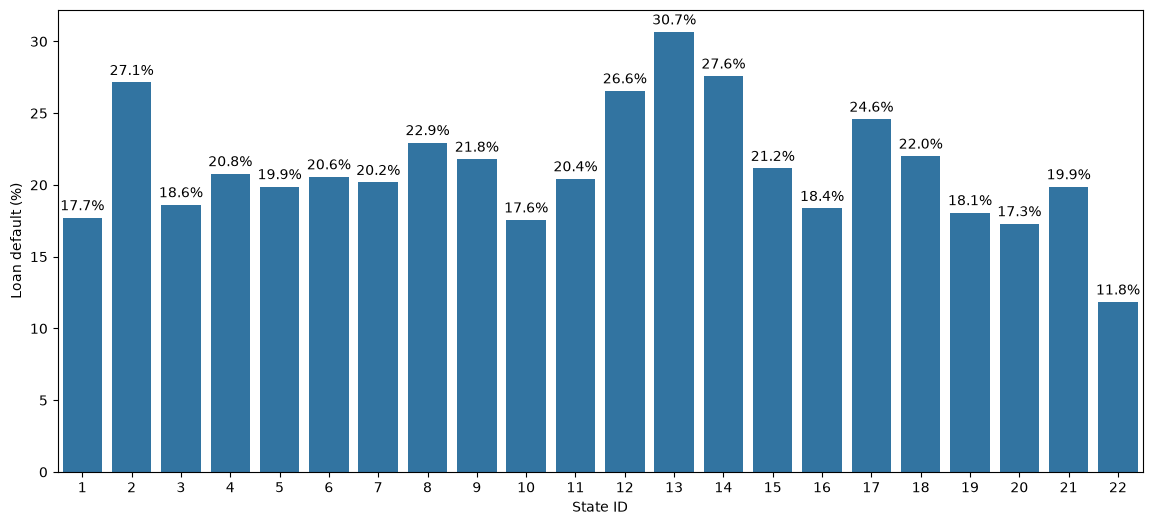

In [21]:
rate_by_state = df.groupby('State_ID')['loan_default'].mean()*100

plt.figure(figsize = (14,6))
ax = sns.barplot(x = rate_by_state.index, y = rate_by_state.values)
plt.xlabel('State ID')
plt.ylabel('Loan default (%)')
ax.bar_label(ax.containers[0], fmt = '%.1f%%', padding = 3)
plt.show()

In [22]:
df.columns

Index(['UniqueID', 'disbursed_amount', 'asset_cost', 'ltv', 'branch_id',
       'supplier_id', 'manufacturer_id', 'Current_pincode_ID', 'Date.of.Birth',
       'Employment.Type', 'DisbursalDate', 'State_ID', 'Employee_code_ID',
       'MobileNo_Avl_Flag', 'Aadhar_flag', 'PAN_flag', 'VoterID_flag',
       'Driving_flag', 'Passport_flag', 'PERFORM_CNS.SCORE',
       'PERFORM_CNS.SCORE.DESCRIPTION', 'PRI.NO.OF.ACCTS', 'PRI.ACTIVE.ACCTS',
       'PRI.OVERDUE.ACCTS', 'PRI.CURRENT.BALANCE', 'PRI.SANCTIONED.AMOUNT',
       'PRI.DISBURSED.AMOUNT', 'SEC.NO.OF.ACCTS', 'SEC.ACTIVE.ACCTS',
       'SEC.OVERDUE.ACCTS', 'SEC.CURRENT.BALANCE', 'SEC.SANCTIONED.AMOUNT',
       'SEC.DISBURSED.AMOUNT', 'PRIMARY.INSTAL.AMT', 'SEC.INSTAL.AMT',
       'NEW.ACCTS.IN.LAST.SIX.MONTHS', 'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS',
       'AVERAGE.ACCT.AGE', 'CREDIT.HISTORY.LENGTH', 'NO.OF_INQUIRIES',
       'loan_default'],
      dtype='str')

In [23]:
df['DisbursalDate'].str[3:5].value_counts()

DisbursalDate
10    98364
08    68002
09    66788
Name: count, dtype: int64

In [24]:
df['DisbursalDate'] = pd.to_datetime(df['DisbursalDate'], format = '%d-%m-%y')

In [25]:
df['DisbursalDate'].dtype

dtype('<M8[us]')

In [26]:
df['DisbursalMonth'] = df['DisbursalDate'].dt.month

In [27]:
df.head()

,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,Date.of.Birth,Employment.Type,...,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,AVERAGE.ACCT.AGE,CREDIT.HISTORY.LENGTH,NO.OF_INQUIRIES,loan_default,DisbursalMonth
0,420825,50578,58400,89.55,67,22807,45,1441,01-01-84,Salaried,...,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0,8
1,537409,47145,65550,73.23,67,22807,45,1502,31-07-85,Self employed,...,0,1991,0,0,1,1yrs 11mon,1yrs 11mon,0,1,9
2,417566,53278,61360,89.63,67,22807,45,1497,24-08-85,Self employed,...,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0,8
3,624493,57513,66113,88.48,67,22807,45,1501,30-12-93,Self employed,...,0,31,0,0,0,0yrs 8mon,1yrs 3mon,1,1,10
4,539055,52378,60300,88.39,67,22807,45,1495,09-12-77,Self employed,...,0,0,0,0,0,0yrs 0mon,0yrs 0mon,1,1,9


In [28]:
# plotting between disbursal month and loan default

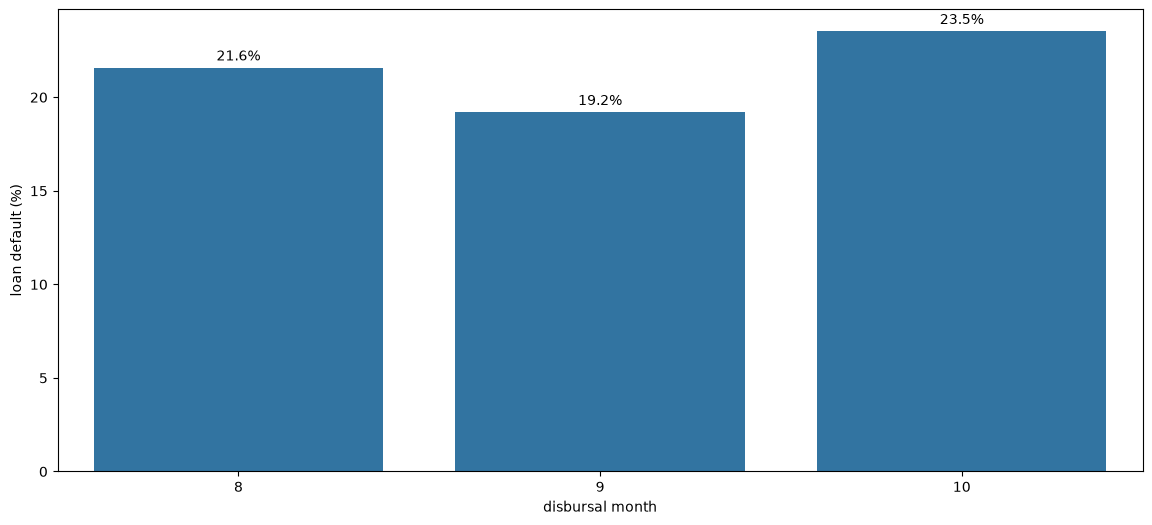

In [29]:
month_default = df.groupby('DisbursalMonth')['loan_default'].mean()*100

plt.figure(figsize = (14,6))
ax = sns.barplot(x = month_default.index, y = month_default.values)
ax.bar_label(ax.containers[0], fmt = '%.1f%%', padding = 3)
plt.xlabel('disbursal month')
plt.ylabel('loan default (%)')
plt.show()


In [30]:
df.head()

,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,Date.of.Birth,Employment.Type,...,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,AVERAGE.ACCT.AGE,CREDIT.HISTORY.LENGTH,NO.OF_INQUIRIES,loan_default,DisbursalMonth
0,420825,50578,58400,89.55,67,22807,45,1441,01-01-84,Salaried,...,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0,8
1,537409,47145,65550,73.23,67,22807,45,1502,31-07-85,Self employed,...,0,1991,0,0,1,1yrs 11mon,1yrs 11mon,0,1,9
2,417566,53278,61360,89.63,67,22807,45,1497,24-08-85,Self employed,...,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0,8
3,624493,57513,66113,88.48,67,22807,45,1501,30-12-93,Self employed,...,0,31,0,0,0,0yrs 8mon,1yrs 3mon,1,1,10
4,539055,52378,60300,88.39,67,22807,45,1495,09-12-77,Self employed,...,0,0,0,0,0,0yrs 0mon,0yrs 0mon,1,1,9


In [31]:
df.isnull().sum()

UniqueID                                  0
disbursed_amount                          0
asset_cost                                0
ltv                                       0
branch_id                                 0
supplier_id                               0
manufacturer_id                           0
Current_pincode_ID                        0
Date.of.Birth                             0
Employment.Type                        7661
DisbursalDate                             0
State_ID                                  0
Employee_code_ID                          0
MobileNo_Avl_Flag                         0
Aadhar_flag                               0
PAN_flag                                  0
VoterID_flag                              0
Driving_flag                              0
Passport_flag                             0
PERFORM_CNS.SCORE                         0
PERFORM_CNS.SCORE.DESCRIPTION             0
PRI.NO.OF.ACCTS                           0
PRI.ACTIVE.ACCTS                

In [32]:
df.shape

(233154, 42)

In [33]:
# dropping the null values

In [34]:
#df.dropna(inplace = True)

In [35]:
df.shape

(233154, 42)

In [36]:
df.isnull().sum()

UniqueID                                  0
disbursed_amount                          0
asset_cost                                0
ltv                                       0
branch_id                                 0
supplier_id                               0
manufacturer_id                           0
Current_pincode_ID                        0
Date.of.Birth                             0
Employment.Type                        7661
DisbursalDate                             0
State_ID                                  0
Employee_code_ID                          0
MobileNo_Avl_Flag                         0
Aadhar_flag                               0
PAN_flag                                  0
VoterID_flag                              0
Driving_flag                              0
Passport_flag                             0
PERFORM_CNS.SCORE                         0
PERFORM_CNS.SCORE.DESCRIPTION             0
PRI.NO.OF.ACCTS                           0
PRI.ACTIVE.ACCTS                

In [37]:
df.duplicated().sum()

np.int64(0)

In [38]:
df.columns

Index(['UniqueID', 'disbursed_amount', 'asset_cost', 'ltv', 'branch_id',
       'supplier_id', 'manufacturer_id', 'Current_pincode_ID', 'Date.of.Birth',
       'Employment.Type', 'DisbursalDate', 'State_ID', 'Employee_code_ID',
       'MobileNo_Avl_Flag', 'Aadhar_flag', 'PAN_flag', 'VoterID_flag',
       'Driving_flag', 'Passport_flag', 'PERFORM_CNS.SCORE',
       'PERFORM_CNS.SCORE.DESCRIPTION', 'PRI.NO.OF.ACCTS', 'PRI.ACTIVE.ACCTS',
       'PRI.OVERDUE.ACCTS', 'PRI.CURRENT.BALANCE', 'PRI.SANCTIONED.AMOUNT',
       'PRI.DISBURSED.AMOUNT', 'SEC.NO.OF.ACCTS', 'SEC.ACTIVE.ACCTS',
       'SEC.OVERDUE.ACCTS', 'SEC.CURRENT.BALANCE', 'SEC.SANCTIONED.AMOUNT',
       'SEC.DISBURSED.AMOUNT', 'PRIMARY.INSTAL.AMT', 'SEC.INSTAL.AMT',
       'NEW.ACCTS.IN.LAST.SIX.MONTHS', 'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS',
       'AVERAGE.ACCT.AGE', 'CREDIT.HISTORY.LENGTH', 'NO.OF_INQUIRIES',
       'loan_default', 'DisbursalMonth'],
      dtype='str')

### outlier analysis

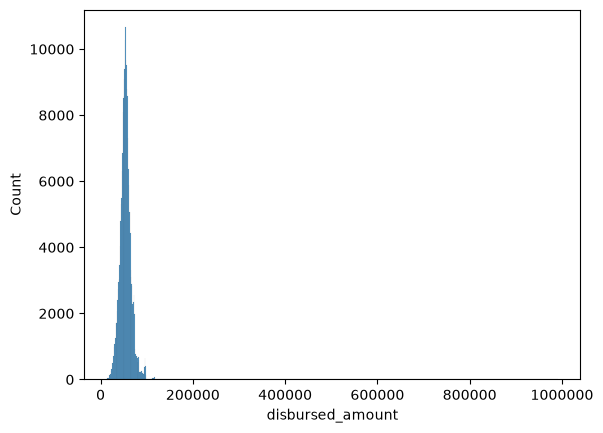

In [39]:
plt.ticklabel_format(style = 'plain', axis = 'x')
sns.histplot(data = df, x = 'disbursed_amount')
plt.show()

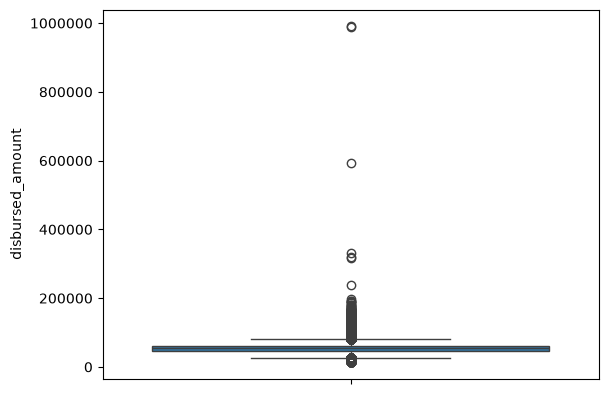

In [40]:
plt.ticklabel_format(style = 'plain', axis = 'y')
sns.boxplot(data = df, y = 'disbursed_amount')
plt.show()

In [41]:
q1 = df['disbursed_amount'].quantile(0.25)
q2 = df['disbursed_amount'].median()
q3 = df['disbursed_amount'].quantile(0.75)

iqr = q3 - q1

outliers = df[(df['disbursed_amount'] > (q3 + (1.5 * iqr))) | (df['disbursed_amount'] < (q1 - (1.5*iqr)))]

In [42]:
print('lower bound:', q1 - 1.5*iqr)

lower bound: 27243.0


In [43]:
print('upper bound:', q3 + 1.5*iqr)

upper bound: 80315.0


In [44]:
outliers.shape

(9868, 42)

In [45]:
outliers

,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,Date.of.Birth,Employment.Type,...,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,AVERAGE.ACCT.AGE,CREDIT.HISTORY.LENGTH,NO.OF_INQUIRIES,loan_default,DisbursalMonth
171,437939,27229,61865,44.77,34,15196,86,992,10-04-91,Salaried,...,0,0,0,1,0,0yrs 6mon,0yrs 11mon,0,0,8
243,537614,22574,48610,47.32,34,23069,51,992,01-01-59,Self employed,...,0,0,0,0,0,4yrs 7mon,4yrs 7mon,0,0,9
329,429860,20574,39605,55.55,130,20700,48,1047,09-10-66,Self employed,...,0,7078,0,1,0,0yrs 10mon,1yrs 8mon,0,0,8
419,594868,26529,65610,42.68,34,18680,45,1030,01-06-87,Self employed,...,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0,10
435,461239,19574,60640,34.63,34,18680,45,1019,12-05-95,Self employed,...,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
232926,516122,80986,113500,74.89,74,17436,48,2584,10-01-92,Self employed,...,0,2551,0,0,0,0yrs 6mon,0yrs 6mon,0,0,9
232932,459488,25969,41281,67.83,74,17436,48,2584,01-01-91,Salaried,...,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,1,8
232950,629715,81833,119588,71.08,74,17436,48,2578,01-01-73,Salaried,...,0,1533,0,1,0,5yrs 8mon,11yrs 3mon,1,0,10
232957,521668,23074,47229,52.93,74,17436,48,2598,05-05-86,Salaried,...,0,2522,0,2,0,1yrs 3mon,2yrs 11mon,0,0,9


In [46]:
# percentage of outliers

len(outliers)/len(df) * 100

4.2323957555950145

In [47]:
outliers.describe()

,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,DisbursalDate,State_ID,...,SEC.CURRENT.BALANCE,SEC.SANCTIONED.AMOUNT,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,NO.OF_INQUIRIES,loan_default,DisbursalMonth
count,9868.000000,9868.000000,9.868000e+03,9868.000000,9868.000000,9868.000000,9868.000000,9868.000000,9868,9868.000000,...,9.868000e+03,9.868000e+03,9.868000e+03,9.868000e+03,9868.000000,9868.000000,9868.000000,9868.000000,9868.000000,9868.000000
mean,545170.982671,74443.701358,1.184605e+05,62.507813,78.184232,20655.062221,63.139947,3979.258310,2018-09-27 04:40:45.723550,6.848196,...,4.404038e+03,5.737040e+03,5.652411e+03,1.324441e+04,208.008816,0.384678,0.103567,0.207945,0.221423,9.250709
min,417450.000000,13320.000000,3.712900e+04,10.030000,1.000000,12312.000000,45.000000,4.000000,2018-08-01 00:00:00,1.000000,...,-1.713000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000
25%,487386.250000,26923.250000,8.504200e+04,52.820000,11.000000,17412.000000,48.000000,1756.000000,2018-09-03 00:00:00,3.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000
50%,553851.000000,84620.000000,1.189250e+05,67.660000,61.000000,22601.000000,51.000000,3871.500000,2018-09-30 00:00:00,5.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000
75%,602438.000000,95010.000000,1.483310e+05,74.420000,136.000000,23478.000000,67.000000,6064.250000,2018-10-22 00:00:00,9.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+03,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000
max,658664.000000,990572.000000,1.628992e+06,94.950000,261.000000,24779.000000,156.000000,7336.000000,2018-10-31 00:00:00,22.000000,...,4.632595e+06,4.850000e+06,4.850000e+06,3.750505e+06,370500.000000,14.000000,12.000000,9.000000,1.000000,10.000000
std,67347.309620,35674.714273,4.555740e+04,16.580199,75.591106,3486.849441,20.499028,2289.945058,NaN,4.334997,...,8.731344e+04,1.014334e+05,1.013474e+05,9.780740e+04,6550.272506,0.943620,0.400941,0.643457,0.415225,0.825124


In [48]:
print('number of lower outliers:', (df['disbursed_amount'] < 27303).sum())

number of lower outliers: 2631


In [49]:
print('number of upper outliers:', (df['disbursed_amount'] > 79959).sum())

number of upper outliers: 7456


In [50]:
outliers.groupby('loan_default')['disbursed_amount'].describe()

,count,mean,std,min,25%,50%,75%,max
loan_default,,,,,,,,
0,7683.0,72709.747625,37554.392378,13320.0,26529.0,84033.0,94914.0,990572.0
1,2185.0,80540.711213,27227.571820,13369.0,81686.0,86489.0,95490.0,191392.0


In [51]:
print('outlier default:' , outliers['loan_default'].mean())
print('overall default:', df['loan_default'].mean())

outlier default: 0.2214227807053101
overall default: 0.2170711203753742


In [52]:
# comparing default rates between outliers and non outliers

non_outliers = df.drop(outliers.index)

print('outlier default:' , outliers['loan_default'].mean() * 100)
print('non-outlier default:', non_outliers['loan_default'].mean() * 100)

outlier default: 22.14227807053101
non-outlier default: 21.68788011787573


The disbursed_amount feature contains 9,546 potential outliers based on the IQR method. Outlier loans have a default rate of 22.03%, compared with 21.70% for non-outlier loans. The difference is minimal, so there is currently no compelling reason to remove these observations solely because they are statistical outliers.

In [53]:
df['ltv'].describe()

count    233154.000000
mean         74.746530
std          11.456636
min          10.030000
25%          68.880000
50%          76.800000
75%          83.670000
max          95.000000
Name: ltv, dtype: float64

In [54]:
df['ltv'].skew()

np.float64(-1.0757660644024194)

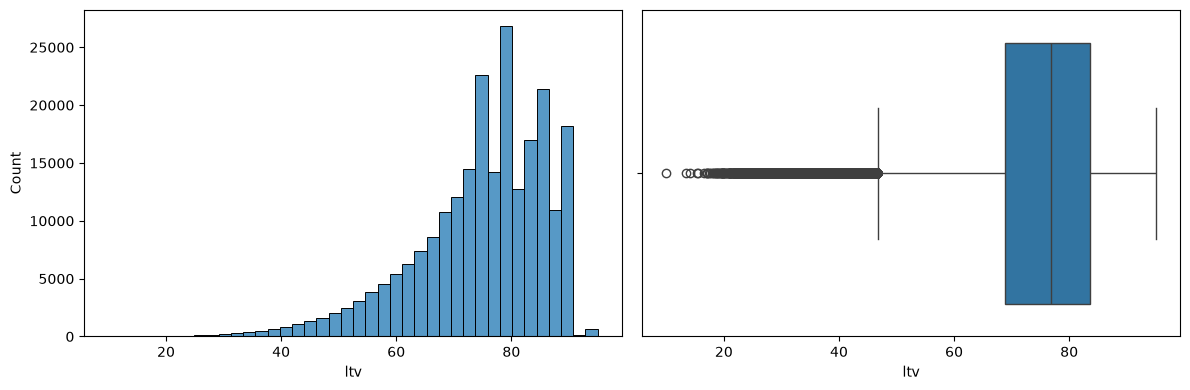

In [55]:
fig, axes = plt.subplots(1, 2, figsize = (12,4))

sns.histplot(df['ltv'], bins = 40, ax = axes[0])
sns.boxplot(data = df, x = 'ltv', ax = axes[1])

plt.tight_layout()
plt.show()

In [56]:
df.groupby(pd.cut(df['ltv'], bins = [0, 40, 60, 70, 80, 90, 100]), observed = True)['loan_default'].agg(
['count', 'mean'])

,count,mean
ltv,,
"(0, 40]",2613,0.130501
"(40, 60]",23476,0.139973
"(60, 70]",39573,0.177116
"(70, 80]",85604,0.219931
"(80, 90]",81005,0.258824
"(90, 100]",883,0.206116


we see that default rate is increasing as the ltv value is increasing

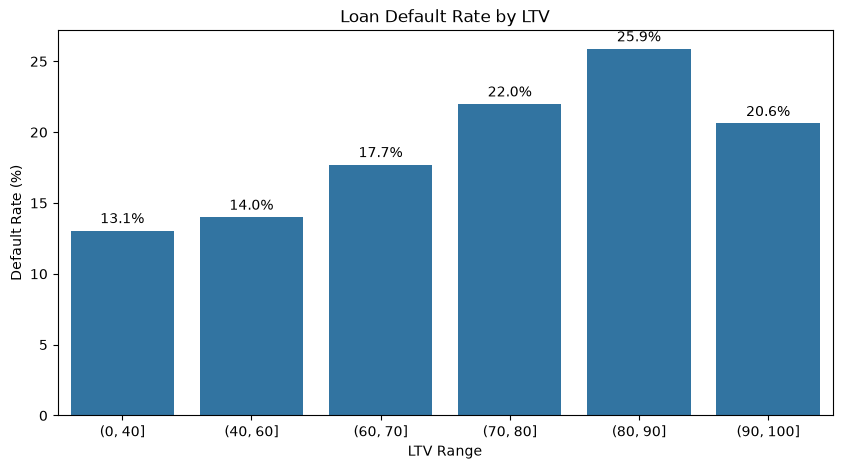

In [57]:
ltv_stats = df.groupby(
    pd.cut(df['ltv'], bins=[0, 40, 60, 70, 80, 90, 100]),
    observed=True
)['loan_default'].agg(['count', 'mean'])

ltv_stats['mean'] *= 100

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=ltv_stats.index.astype(str),
    y=ltv_stats['mean']
)

ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)

plt.xlabel('LTV Range')
plt.ylabel('Default Rate (%)')
plt.title('Loan Default Rate by LTV')
plt.show()

Default rates generally increase with LTV up to 90%. The smaller 90–100% group shows a lower observed default rate, which may warrant further investigation.

In [58]:
df.columns

Index(['UniqueID', 'disbursed_amount', 'asset_cost', 'ltv', 'branch_id',
       'supplier_id', 'manufacturer_id', 'Current_pincode_ID', 'Date.of.Birth',
       'Employment.Type', 'DisbursalDate', 'State_ID', 'Employee_code_ID',
       'MobileNo_Avl_Flag', 'Aadhar_flag', 'PAN_flag', 'VoterID_flag',
       'Driving_flag', 'Passport_flag', 'PERFORM_CNS.SCORE',
       'PERFORM_CNS.SCORE.DESCRIPTION', 'PRI.NO.OF.ACCTS', 'PRI.ACTIVE.ACCTS',
       'PRI.OVERDUE.ACCTS', 'PRI.CURRENT.BALANCE', 'PRI.SANCTIONED.AMOUNT',
       'PRI.DISBURSED.AMOUNT', 'SEC.NO.OF.ACCTS', 'SEC.ACTIVE.ACCTS',
       'SEC.OVERDUE.ACCTS', 'SEC.CURRENT.BALANCE', 'SEC.SANCTIONED.AMOUNT',
       'SEC.DISBURSED.AMOUNT', 'PRIMARY.INSTAL.AMT', 'SEC.INSTAL.AMT',
       'NEW.ACCTS.IN.LAST.SIX.MONTHS', 'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS',
       'AVERAGE.ACCT.AGE', 'CREDIT.HISTORY.LENGTH', 'NO.OF_INQUIRIES',
       'loan_default', 'DisbursalMonth'],
      dtype='str')

In [59]:
df['PERFORM_CNS.SCORE'].describe()

count    233154.000000
mean        289.462994
std         338.374779
min           0.000000
25%           0.000000
50%           0.000000
75%         678.000000
max         890.000000
Name: PERFORM_CNS.SCORE, dtype: float64

In [60]:
df['PERFORM_CNS.SCORE'].value_counts().head(20)

PERFORM_CNS.SCORE
0      116950
300      8776
738      8662
825      7393
15       3765
17       3672
763      3026
16       2885
708      2104
737      1989
836      1927
18       1534
749      1406
710      1245
680      1075
832      1049
726      1042
681      1031
706       985
14        976
Name: count, dtype: int64

In [61]:
df[df['PERFORM_CNS.SCORE'] == 0]['PERFORM_CNS.SCORE.DESCRIPTION'].value_counts()

PERFORM_CNS.SCORE.DESCRIPTION
No Bureau History Available    116950
Name: count, dtype: int64

In [62]:
df.loc[
    df['PERFORM_CNS.SCORE'].isin([15, 17, 18, 300]),
    ['PERFORM_CNS.SCORE', 'PERFORM_CNS.SCORE.DESCRIPTION']
].drop_duplicates().sort_values('PERFORM_CNS.SCORE')

,PERFORM_CNS.SCORE,PERFORM_CNS.SCORE.DESCRIPTION
46,15,Not Scored: Sufficient History Not Available
7,17,Not Scored: Not Enough Info available on the c...
72,18,Not Scored: No Updates available in last 36 mo...
10,300,M-Very High Risk


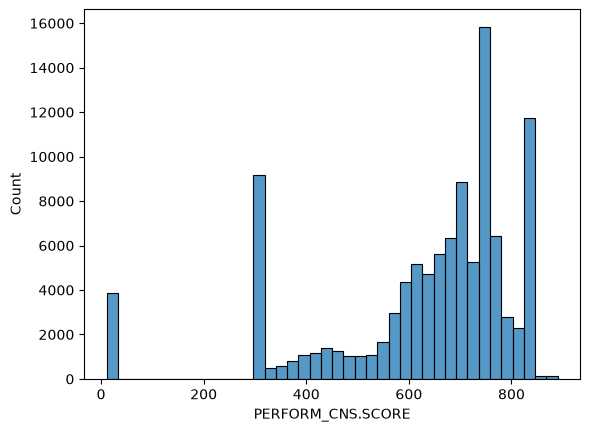

In [63]:
scored = df[~df['PERFORM_CNS.SCORE'].isin([0, 15, 17, 18])]

sns.histplot(data=scored, x='PERFORM_CNS.SCORE', bins=40)
plt.show()

In [64]:
df.groupby('PERFORM_CNS.SCORE.DESCRIPTION')['PERFORM_CNS.SCORE'].agg(
    ['count', 'min', 'max']
).sort_values('min')

,count,min,max
PERFORM_CNS.SCORE.DESCRIPTION,,,
No Bureau History Available,116950,0,0
Not Scored: More than 50 active Accounts found,3,11,11
Not Scored: Only a Guarantor,976,14,14
Not Scored: Sufficient History Not Available,3765,15,15
Not Scored: No Activity seen on the customer (Inactive),2885,16,16
Not Scored: Not Enough Info available on the customer,3672,17,17
Not Scored: No Updates available in last 36 months,1534,18,18
M-Very High Risk,8776,300,300
L-Very High Risk,1134,301,350


<Axes: xlabel='PERFORM_CNS.SCORE', ylabel='Count'>

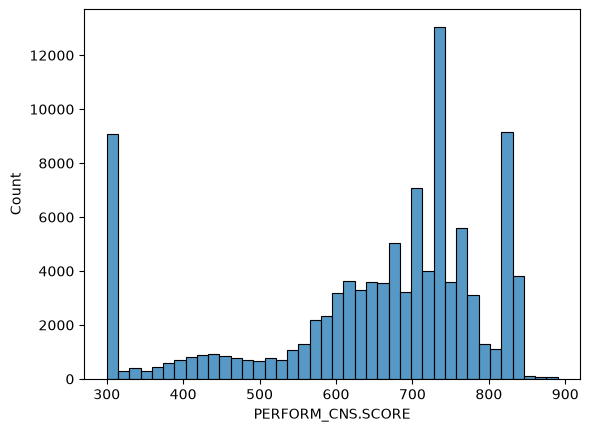

In [65]:
scored = df[df['PERFORM_CNS.SCORE']>= 300]

sns.histplot(data = scored, x = 'PERFORM_CNS.SCORE', bins = 40)

In [66]:
df.groupby('PERFORM_CNS.SCORE.DESCRIPTION')['loan_default'].agg(['count', 'mean']).sort_values('mean', ascending = False)

,count,mean
PERFORM_CNS.SCORE.DESCRIPTION,,
M-Very High Risk,8776,0.304581
L-Very High Risk,1134,0.280423
K-High Risk,8277,0.278120
I-Medium Risk,5557,0.272629
Not Scored: Sufficient History Not Available,3765,0.255777
J-High Risk,3748,0.252401
H-Medium Risk,6855,0.241867
No Bureau History Available,116950,0.231313
Not Scored: Only a Guarantor,976,0.213115


Borrowers assigned higher credit risk generally have higher observed default rates

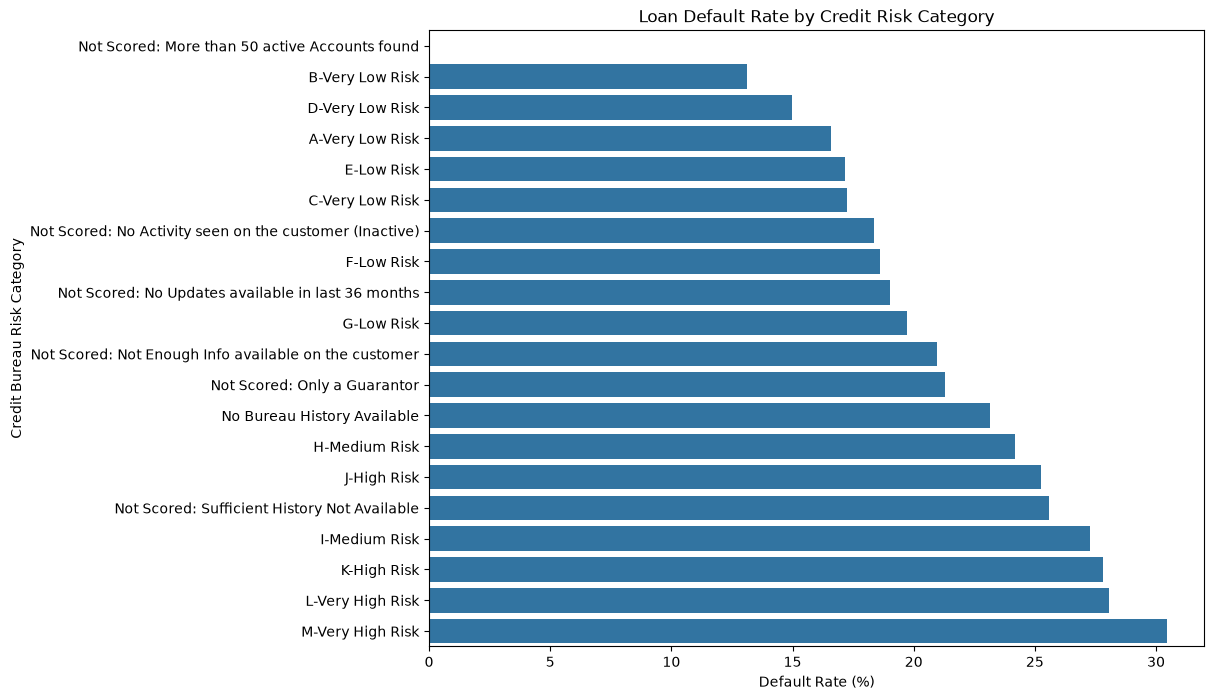

In [67]:
score_stats = df.groupby(
    'PERFORM_CNS.SCORE.DESCRIPTION'
)['loan_default'].agg(['count', 'mean'])

score_stats['mean'] *= 100

score_stats = score_stats.sort_values('mean')

plt.figure(figsize=(10, 8))

ax = sns.barplot(
    x=score_stats['mean'],
    y=score_stats.index
)

plt.xlabel('Default Rate (%)')
plt.ylabel('Credit Bureau Risk Category')
plt.title('Loan Default Rate by Credit Risk Category')
plt.show()

The score column contains special codes for unscored borrowers.

Genuine scores have a non-uniform distribution.

Credit risk categories show meaningful differences in default rates.

In [68]:
df.columns

Index(['UniqueID', 'disbursed_amount', 'asset_cost', 'ltv', 'branch_id',
       'supplier_id', 'manufacturer_id', 'Current_pincode_ID', 'Date.of.Birth',
       'Employment.Type', 'DisbursalDate', 'State_ID', 'Employee_code_ID',
       'MobileNo_Avl_Flag', 'Aadhar_flag', 'PAN_flag', 'VoterID_flag',
       'Driving_flag', 'Passport_flag', 'PERFORM_CNS.SCORE',
       'PERFORM_CNS.SCORE.DESCRIPTION', 'PRI.NO.OF.ACCTS', 'PRI.ACTIVE.ACCTS',
       'PRI.OVERDUE.ACCTS', 'PRI.CURRENT.BALANCE', 'PRI.SANCTIONED.AMOUNT',
       'PRI.DISBURSED.AMOUNT', 'SEC.NO.OF.ACCTS', 'SEC.ACTIVE.ACCTS',
       'SEC.OVERDUE.ACCTS', 'SEC.CURRENT.BALANCE', 'SEC.SANCTIONED.AMOUNT',
       'SEC.DISBURSED.AMOUNT', 'PRIMARY.INSTAL.AMT', 'SEC.INSTAL.AMT',
       'NEW.ACCTS.IN.LAST.SIX.MONTHS', 'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS',
       'AVERAGE.ACCT.AGE', 'CREDIT.HISTORY.LENGTH', 'NO.OF_INQUIRIES',
       'loan_default', 'DisbursalMonth'],
      dtype='str')

In [69]:
df['PRI.OVERDUE.ACCTS'].describe()

count    233154.000000
mean          0.156549
std           0.548787
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          25.000000
Name: PRI.OVERDUE.ACCTS, dtype: float64

In [70]:
df['PRI.OVERDUE.ACCTS'].value_counts().sort_index()

PRI.OVERDUE.ACCTS
0     206879
1      19970
2       4302
3       1202
4        404
5        166
6         96
7         38
8         27
9         25
10         6
11        12
12         8
13         5
14         5
15         1
16         1
17         2
18         2
19         1
23         1
25         1
Name: count, dtype: int64

In [71]:
overdue_groups = pd.cut(
    df['PRI.OVERDUE.ACCTS'],
    bins=[-1, 0, 1, 2, float('inf')],
    labels=['0', '1', '2', '3+']
)

overdue_stats = df.groupby(
    overdue_groups, observed=True
)['loan_default'].agg(['count', 'mean'])

overdue_stats['mean'] *= 100
overdue_stats

,count,mean
PRI.OVERDUE.ACCTS,,
0,206879,20.982313
1,19970,26.950426
2,4302,28.847048
3+,2003,28.956565


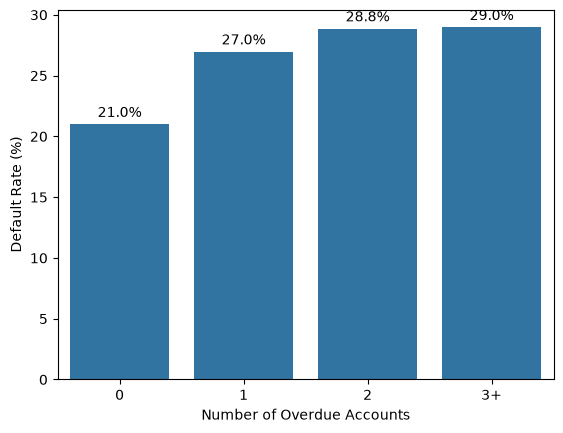

In [72]:
ax = sns.barplot(
    x=overdue_stats.index,
    y=overdue_stats['mean']
)

ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)

plt.xlabel('Number of Overdue Accounts')
plt.ylabel('Default Rate (%)')
plt.show()

Borrowers with no overdue accounts have the lowest default rate.

Having even one overdue account is associated with a 5.9 percentage-point increase in default rate.

Default rates continue to increase with additional overdue accounts, although the increase becomes smaller.

Loan default rates increase from 21.0% among borrowers with no overdue accounts to approximately 29.0% among those with three or more. This suggests that existing overdue accounts may be associated with greater default risk.

In [73]:
df.columns

Index(['UniqueID', 'disbursed_amount', 'asset_cost', 'ltv', 'branch_id',
       'supplier_id', 'manufacturer_id', 'Current_pincode_ID', 'Date.of.Birth',
       'Employment.Type', 'DisbursalDate', 'State_ID', 'Employee_code_ID',
       'MobileNo_Avl_Flag', 'Aadhar_flag', 'PAN_flag', 'VoterID_flag',
       'Driving_flag', 'Passport_flag', 'PERFORM_CNS.SCORE',
       'PERFORM_CNS.SCORE.DESCRIPTION', 'PRI.NO.OF.ACCTS', 'PRI.ACTIVE.ACCTS',
       'PRI.OVERDUE.ACCTS', 'PRI.CURRENT.BALANCE', 'PRI.SANCTIONED.AMOUNT',
       'PRI.DISBURSED.AMOUNT', 'SEC.NO.OF.ACCTS', 'SEC.ACTIVE.ACCTS',
       'SEC.OVERDUE.ACCTS', 'SEC.CURRENT.BALANCE', 'SEC.SANCTIONED.AMOUNT',
       'SEC.DISBURSED.AMOUNT', 'PRIMARY.INSTAL.AMT', 'SEC.INSTAL.AMT',
       'NEW.ACCTS.IN.LAST.SIX.MONTHS', 'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS',
       'AVERAGE.ACCT.AGE', 'CREDIT.HISTORY.LENGTH', 'NO.OF_INQUIRIES',
       'loan_default', 'DisbursalMonth'],
      dtype='str')

In [74]:
df['Employment.Type'].value_counts()

Employment.Type
Self employed    127635
Salaried          97858
Name: count, dtype: int64

In [75]:
df.groupby('Employment.Type', dropna = False)['loan_default'].mean() * 100

Employment.Type
Salaried         20.345807
Self employed    22.765699
NaN              21.459340
Name: loan_default, dtype: float64

In [76]:
df['loan_default'].value_counts()

loan_default
0    182543
1     50611
Name: count, dtype: int64

In [77]:
df.columns.to_list()

['UniqueID',
 'disbursed_amount',
 'asset_cost',
 'ltv',
 'branch_id',
 'supplier_id',
 'manufacturer_id',
 'Current_pincode_ID',
 'Date.of.Birth',
 'Employment.Type',
 'DisbursalDate',
 'State_ID',
 'Employee_code_ID',
 'MobileNo_Avl_Flag',
 'Aadhar_flag',
 'PAN_flag',
 'VoterID_flag',
 'Driving_flag',
 'Passport_flag',
 'PERFORM_CNS.SCORE',
 'PERFORM_CNS.SCORE.DESCRIPTION',
 'PRI.NO.OF.ACCTS',
 'PRI.ACTIVE.ACCTS',
 'PRI.OVERDUE.ACCTS',
 'PRI.CURRENT.BALANCE',
 'PRI.SANCTIONED.AMOUNT',
 'PRI.DISBURSED.AMOUNT',
 'SEC.NO.OF.ACCTS',
 'SEC.ACTIVE.ACCTS',
 'SEC.OVERDUE.ACCTS',
 'SEC.CURRENT.BALANCE',
 'SEC.SANCTIONED.AMOUNT',
 'SEC.DISBURSED.AMOUNT',
 'PRIMARY.INSTAL.AMT',
 'SEC.INSTAL.AMT',
 'NEW.ACCTS.IN.LAST.SIX.MONTHS',
 'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS',
 'AVERAGE.ACCT.AGE',
 'CREDIT.HISTORY.LENGTH',
 'NO.OF_INQUIRIES',
 'loan_default',
 'DisbursalMonth']

In [78]:
df.dtypes

UniqueID                                        int64
disbursed_amount                                int64
asset_cost                                      int64
ltv                                           float64
branch_id                                       int64
supplier_id                                     int64
manufacturer_id                                 int64
Current_pincode_ID                              int64
Date.of.Birth                                     str
Employment.Type                                   str
DisbursalDate                          datetime64[us]
State_ID                                        int64
Employee_code_ID                                int64
MobileNo_Avl_Flag                               int64
Aadhar_flag                                     int64
PAN_flag                                        int64
VoterID_flag                                    int64
Driving_flag                                    int64
Passport_flag               

In [79]:
df['AVERAGE.ACCT.AGE']

0          0yrs 0mon
1         1yrs 11mon
2          0yrs 0mon
3          0yrs 8mon
4          0yrs 0mon
             ...    
233149     1yrs 9mon
233150     0yrs 6mon
233151     0yrs 0mon
233152     0yrs 0mon
233153     0yrs 0mon
Name: AVERAGE.ACCT.AGE, Length: 233154, dtype: str

In [80]:
df['CREDIT.HISTORY.LENGTH']

0          0yrs 0mon
1         1yrs 11mon
2          0yrs 0mon
3          1yrs 3mon
4          0yrs 0mon
             ...    
233149     3yrs 3mon
233150     0yrs 6mon
233151     0yrs 0mon
233152     0yrs 0mon
233153     0yrs 0mon
Name: CREDIT.HISTORY.LENGTH, Length: 233154, dtype: str

In [81]:
df[['Date.of.Birth',
    'AVERAGE.ACCT.AGE',
    'CREDIT.HISTORY.LENGTH']].head(10)

,Date.of.Birth,AVERAGE.ACCT.AGE,CREDIT.HISTORY.LENGTH
0,01-01-84,0yrs 0mon,0yrs 0mon
1,31-07-85,1yrs 11mon,1yrs 11mon
2,24-08-85,0yrs 0mon,0yrs 0mon
3,30-12-93,0yrs 8mon,1yrs 3mon
4,09-12-77,0yrs 0mon,0yrs 0mon
5,08-09-90,1yrs 9mon,2yrs 0mon
6,01-06-88,0yrs 0mon,0yrs 0mon
7,04-10-89,0yrs 2mon,0yrs 2mon
8,15-11-91,4yrs 8mon,4yrs 8mon
9,01-06-68,1yrs 7mon,1yrs 7mon


In [82]:
df[['branch_id', 'supplier_id', 'manufacturer_id',
    'Employee_code_ID', 'Current_pincode_ID']].nunique()

branch_id               82
supplier_id           2953
manufacturer_id         11
Employee_code_ID      3270
Current_pincode_ID    6698
dtype: int64

In [83]:
for col in ['AVERAGE.ACCT.AGE', 'CREDIT.HISTORY.LENGTH']:
    parts = df[col].str.extract(r'(\d+)yrs\s+(\d+)mon')
    df[col + '_months'] = (
        parts[0].astype(int) * 12 + parts[1].astype(int)
    )

In [84]:
df[['AVERAGE.ACCT.AGE', 'AVERAGE.ACCT.AGE_months',
    'CREDIT.HISTORY.LENGTH', 'CREDIT.HISTORY.LENGTH_months']].head()

,AVERAGE.ACCT.AGE,AVERAGE.ACCT.AGE_months,CREDIT.HISTORY.LENGTH,CREDIT.HISTORY.LENGTH_months
0,0yrs 0mon,0,0yrs 0mon,0
1,1yrs 11mon,23,1yrs 11mon,23
2,0yrs 0mon,0,0yrs 0mon,0
3,0yrs 8mon,8,1yrs 3mon,15
4,0yrs 0mon,0,0yrs 0mon,0


In [85]:
df[['Date.of.Birth', 'DisbursalDate']].head(20)

,Date.of.Birth,DisbursalDate
0,01-01-84,2018-08-03
1,31-07-85,2018-09-26
2,24-08-85,2018-08-01
3,30-12-93,2018-10-26
4,09-12-77,2018-09-26
5,08-09-90,2018-09-19
6,01-06-88,2018-09-23
7,04-10-89,2018-09-16
8,15-11-91,2018-09-05
9,01-06-68,2018-09-16


In [86]:
df['Date.of.Birth'] = pd.to_datetime(df['Date.of.Birth'], format = '%d-%m-%y', errors = 'coerce')

In [87]:
df['Date.of.Birth'].dt.year.value_counts().sort_index().tail(15)

Date.of.Birth
2054      21
2055     169
2056     337
2057     412
2058     621
2059     816
2060    1241
2061    1173
2062    1478
2063    1556
2064    1773
2065    2397
2066    2268
2067    2522
2068    3081
Name: count, dtype: int64

In [88]:
mask = df['Date.of.Birth'].dt.year > df['DisbursalDate'].dt.year

df.loc[mask, 'Date.of.Birth'] = (
    df.loc[mask, 'Date.of.Birth'] - pd.DateOffset(years=100)
)

In [89]:
df['Date.of.Birth'].dt.year.value_counts().sort_index().tail(15)

Date.of.Birth
1986     8441
1987     8633
1988     9232
1989     8903
1990    10116
1991     9385
1992    10390
1993    10007
1994    10530
1995    10584
1996    10211
1997     7489
1998     2188
1999     1604
2000      632
Name: count, dtype: int64

In [90]:
dob = df['Date.of.Birth']
disb = df['DisbursalDate']

df['Age'] = (
    disb.dt.year - dob.dt.year
    - (
        (disb.dt.month < dob.dt.month) |
        ((disb.dt.month == dob.dt.month) & (disb.dt.day < dob.dt.day))
    )
)

In [91]:
df['Age'].describe()

count    233154.000000
mean         33.939358
std           9.818514
min          18.000000
25%          26.000000
50%          32.000000
75%          41.000000
max          69.000000
Name: Age, dtype: float64

In [92]:
df.drop(columns=['Date.of.Birth'], inplace=True)

/var/folders/bf/76rc9pvx4y95pxbrlkk63m5m0000gn/T/ipykernel_44360/2483018627.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Date.of.Birth'], inplace=True)


In [93]:
df.dtypes

UniqueID                                        int64
disbursed_amount                                int64
asset_cost                                      int64
ltv                                           float64
branch_id                                       int64
supplier_id                                     int64
manufacturer_id                                 int64
Current_pincode_ID                              int64
Employment.Type                                   str
DisbursalDate                          datetime64[us]
State_ID                                        int64
Employee_code_ID                                int64
MobileNo_Avl_Flag                               int64
Aadhar_flag                                     int64
PAN_flag                                        int64
VoterID_flag                                    int64
Driving_flag                                    int64
Passport_flag                                   int64
PERFORM_CNS.SCORE           

In [94]:
df.drop(columns=[
    'AVERAGE.ACCT.AGE',
    'CREDIT.HISTORY.LENGTH',
    'UniqueID'
], inplace=True)

/var/folders/bf/76rc9pvx4y95pxbrlkk63m5m0000gn/T/ipykernel_44360/2286944460.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=[


In [95]:
df.shape

(233154, 41)

In [96]:
df.nunique().sort_values().head(15)

MobileNo_Avl_Flag                       1
loan_default                            2
Passport_flag                           2
Driving_flag                            2
Employment.Type                         2
VoterID_flag                            2
Aadhar_flag                             2
PAN_flag                                2
DisbursalMonth                          3
SEC.OVERDUE.ACCTS                       9
manufacturer_id                        11
DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS    14
PERFORM_CNS.SCORE.DESCRIPTION          20
State_ID                               22
PRI.OVERDUE.ACCTS                      22
dtype: int64

In [97]:
df[[
    'branch_id',
    'supplier_id',
    'manufacturer_id',
    'Current_pincode_ID',
    'Employee_code_ID',
    'State_ID'
]].nunique()

branch_id               82
supplier_id           2953
manufacturer_id         11
Current_pincode_ID    6698
Employee_code_ID      3270
State_ID                22
dtype: int64

In [98]:
df['MobileNo_Avl_Flag'].value_counts()

MobileNo_Avl_Flag
1    233154
Name: count, dtype: int64

In [99]:
df.drop(columns=[
    'MobileNo_Avl_Flag',
    'supplier_id',
    'Current_pincode_ID',
    'Employee_code_ID'
], inplace = True)

/var/folders/bf/76rc9pvx4y95pxbrlkk63m5m0000gn/T/ipykernel_44360/4245284961.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=[


In [100]:
df.shape

(233154, 37)

In [101]:
df['DisbursalDate'].agg(['min', 'max'])
df.groupby(df['DisbursalDate'].dt.to_period('M')).size()

DisbursalDate
2018-08    68002
2018-09    66788
2018-10    98364
Freq: M, dtype: int64

In [102]:
df.groupby('DisbursalMonth')['loan_default'].agg(
    ['count', 'mean']
)

,count,mean
DisbursalMonth,,
8,68002,0.215670
9,66788,0.191876
10,98364,0.235147


### October’s default rate is 23.5% vs 20.4% in training, so expect calibration drift

## preprocessing

In [103]:
df_model = df.copy()

In [104]:
df_model.head()

,disbursed_amount,asset_cost,ltv,branch_id,manufacturer_id,Employment.Type,DisbursalDate,State_ID,Aadhar_flag,PAN_flag,...,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,NO.OF_INQUIRIES,loan_default,DisbursalMonth,AVERAGE.ACCT.AGE_months,CREDIT.HISTORY.LENGTH_months,Age
0,50578,58400,89.55,67,45,Salaried,2018-08-03,6,1,0,...,0,0,0,0,0,0,8,0,0,34
1,47145,65550,73.23,67,45,Self employed,2018-09-26,6,1,0,...,1991,0,0,1,0,1,9,23,23,33
2,53278,61360,89.63,67,45,Self employed,2018-08-01,6,1,0,...,0,0,0,0,0,0,8,0,0,32
3,57513,66113,88.48,67,45,Self employed,2018-10-26,6,1,0,...,31,0,0,0,1,1,10,8,15,24
4,52378,60300,88.39,67,45,Self employed,2018-09-26,6,1,0,...,0,0,0,0,1,1,9,0,0,40


### cns_score has special codes 0–18; handled via description one-hot for now

In [105]:
df_model.dtypes

disbursed_amount                                int64
asset_cost                                      int64
ltv                                           float64
branch_id                                       int64
manufacturer_id                                 int64
Employment.Type                                   str
DisbursalDate                          datetime64[us]
State_ID                                        int64
Aadhar_flag                                     int64
PAN_flag                                        int64
VoterID_flag                                    int64
Driving_flag                                    int64
Passport_flag                                   int64
PERFORM_CNS.SCORE                               int64
PERFORM_CNS.SCORE.DESCRIPTION                     str
PRI.NO.OF.ACCTS                                 int64
PRI.ACTIVE.ACCTS                                int64
PRI.OVERDUE.ACCTS                               int64
PRI.CURRENT.BALANCE         

In [106]:
cols_to_convert = ['branch_id', 'manufacturer_id', 'State_ID']

df_model[cols_to_convert] = df_model[cols_to_convert].astype(str)

In [107]:
df_model.dtypes

disbursed_amount                                int64
asset_cost                                      int64
ltv                                           float64
branch_id                                         str
manufacturer_id                                   str
Employment.Type                                   str
DisbursalDate                          datetime64[us]
State_ID                                          str
Aadhar_flag                                     int64
PAN_flag                                        int64
VoterID_flag                                    int64
Driving_flag                                    int64
Passport_flag                                   int64
PERFORM_CNS.SCORE                               int64
PERFORM_CNS.SCORE.DESCRIPTION                     str
PRI.NO.OF.ACCTS                                 int64
PRI.ACTIVE.ACCTS                                int64
PRI.OVERDUE.ACCTS                               int64
PRI.CURRENT.BALANCE         

In [108]:
y = df_model['loan_default']

split = ['DisbursalDate', 'DisbursalMonth']

cat_cols = ['branch_id', 'manufacturer_id', 'Employment.Type', 'State_ID', 'PERFORM_CNS.SCORE.DESCRIPTION']


num_cols = ['disbursed_amount', 'asset_cost' , 'ltv', 'Aadhar_flag', 'PAN_flag', 'VoterID_flag', 
              'Driving_flag', 'Passport_flag', 'PERFORM_CNS.SCORE', 'PRI.NO.OF.ACCTS', 'PRI.ACTIVE.ACCTS',
             'PRI.OVERDUE.ACCTS', 'PRI.CURRENT.BALANCE', 'PRI.SANCTIONED.AMOUNT', 'PRI.DISBURSED.AMOUNT', 
              'SEC.NO.OF.ACCTS', 'SEC.ACTIVE.ACCTS', 'SEC.OVERDUE.ACCTS', 'SEC.CURRENT.BALANCE', 
              'SEC.SANCTIONED.AMOUNT', 'SEC.DISBURSED.AMOUNT', 'PRIMARY.INSTAL.AMT', 'SEC.INSTAL.AMT',
             'NEW.ACCTS.IN.LAST.SIX.MONTHS', 'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS', 'NO.OF_INQUIRIES',
             'AVERAGE.ACCT.AGE_months', 'CREDIT.HISTORY.LENGTH_months', 'Age']

In [109]:
len(num_cols + cat_cols + split) + 1

37

In [110]:
(df_model.shape[1])

37

In [111]:
X = df_model[num_cols + cat_cols]
y = df_model['loan_default']

In [112]:
from sklearn.model_selection import train_test_split

In [113]:
X_train_rand, X_test_rand, y_train_rand, y_test_rand = train_test_split(X, y, test_size = 0.2, 
                                                                        stratify=y, random_state = 2)

In [114]:
X_train_rand.shape

(186523, 34)

In [115]:
dates = df_model['DisbursalDate']

In [116]:
train_mask = dates < '2018-10-01'

X_train_oot = X[train_mask]
y_train_oot = y[train_mask]

In [117]:
test_mask = dates >= '2018-10-01'

X_test_oot = X[test_mask]
y_test_oot = y[test_mask]

In [118]:
val_mask = (dates >= '2018-09-16') & (dates < '2018-10-01')

X_val = X[val_mask]
y_val = y[val_mask]

In [119]:
fit_mask = dates <'2018-09-16'

X_fit = X[fit_mask]
y_fit = y[fit_mask]

In [120]:
# rand_train
# rand_test
# train_oot
# test_oot
# val
# fit

In [121]:
pd.DataFrame([{'set': 'rand_train', 'rows': len(y_train_rand), 'default_rate' : y_train_rand.mean()},
{'set':'rand_test', 'rows': len(y_test_rand), 'default_rate' : y_test_rand.mean()},
{'set': 'train_oot', 'rows':len(y_train_oot), 'default_rate':y_train_oot.mean()},
{'set': 'test_oot', 'rows': len(y_test_oot), 'default_rate': y_test_oot.mean()}, 
{'set': 'val', 'rows': len(y_val), 'default_rate': y_val.mean()},
{'set': 'fit', 'rows': len(y_fit), 'default_rate': y_fit.mean()}])

,set,rows,default_rate
0,rand_train,186523,0.217072
1,rand_test,46631,0.217066
2,train_oot,134790,0.203880
3,test_oot,98364,0.235147
4,val,44314,0.191632
5,fit,90476,0.209879


- Random train and random test both default at 21.7%. Shuffling mixes August, September and October loans into both sets. The test set is the same mix of loans the model trained on, so it’s an easy test.
- The out-of-time split shows it. The model trains on loans that default at 20.4% and is tested on October loans at 23.5%. That’s the realistic situation: next month’s borrowers aren’t the same as last month’s.
- Default rates don’t drift in one direction. The second half of September defaults at 19.2%, lower than the fit period (21.0%). October then jumps to 23.5%. So default rates go up and down from period to period.

In [122]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, roc_curve

In [123]:
num_steps = Pipeline([
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler', StandardScaler())
])

In [124]:
cat_steps = Pipeline([
    ('imputer', SimpleImputer(strategy = 'constant', fill_value = 'Missing')),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))
])

In [125]:
prep = ColumnTransformer([
    ('num', num_steps, num_cols),
    ('cat', cat_steps, cat_cols)
])

In [126]:
model = Pipeline([
    ('prep', prep),
    ('clf', LogisticRegression(max_iter=1000))
])

In [127]:
from sklearn.base import clone

In [128]:
model_rand  = clone(model)
model_oot = clone(model)

In [129]:
model_rand.fit(X_train_rand, y_train_rand)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](34,)","['disbursed_amount','asset_cost','ltv',...,'Employment.Type','State_ID', 'PERFORM_CNS.SCORE.DESCRIPTION']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,34
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

In [130]:
y_probs_rand = model_rand.predict_proba(X_test_rand)[:, 1]

In [131]:
roc_auc_score(y_test_rand, y_probs_rand)

0.6483975831214601

In [132]:
model_oot.fit(X_train_oot, y_train_oot)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](34,)","['disbursed_amount','asset_cost','ltv',...,'Employment.Type','State_ID', 'PERFORM_CNS.SCORE.DESCRIPTION']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,34
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

In [133]:
y_probs_oot = model_oot.predict_proba(X_test_oot)[:,1]

In [134]:
roc_auc_score(y_test_oot, y_probs_oot)

0.640535147862807

In [135]:
y_probs_oot.mean()

np.float64(0.1997542876335316)

### training rate 20.4%, predicted 20.0%, actual 23.5%

In [136]:
from sklearn.metrics import RocCurveDisplay

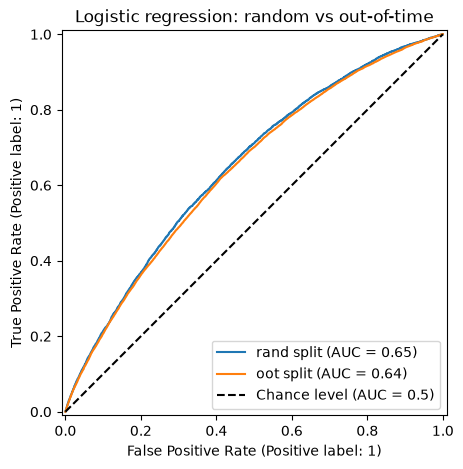

In [137]:
fig, ax = plt.subplots(figsize=(8, 5))

plt.title('Logistic regression: random vs out-of-time')

RocCurveDisplay.from_predictions(y_test_rand, y_probs_rand, ax=ax, name = 'rand split')
RocCurveDisplay.from_predictions(y_test_oot, y_probs_oot, ax = ax, name = 'oot split', plot_chance_level=True)

plt.show()

In [138]:
pip install mlflow

Note: you may need to restart the kernel to use updated packages.


In [139]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment('mlflow-practice')

with mlflow.start_run(run_name = 'first-try'):
    mlflow.log_param('model-type', 'log-reg')
    mlflow.log_param('split', 'oot')
    mlflow.log_metric('auc', 0.641)

2026/11/20 19:01:00 INFO mlflow.tracking.fluent: Experiment with name 'mlflow-practice' does not exist. Creating a new experiment.


In [140]:
def run_experiment(X_train, X_test, y_train, y_test, run_name, split_name):
    fitted = clone(model)
    fitted.fit(X_train, y_train)
    
    probs = fitted.predict_proba(X_test)[:,1]
    auc = roc_auc_score(y_test, probs)
    
    with mlflow.start_run(run_name = run_name):
        mlflow.log_param('split', split_name)
        mlflow.log_param('model_type', type(fitted.named_steps['clf']).__name__)
        mlflow.log_param('train_rows', len(X_train))
        
        mlflow.log_metric('auc', auc)
        mlflow.log_metric('mean_pred', probs.mean())
        mlflow.log_metric('actual_rate', y_test.mean())
        
        mlflow.sklearn.log_model(fitted, name="model", skops_trusted_types=["numpy.dtype"])
        
    print( f"{run_name}: AUC = {auc:.3f}")
    return fitted, probs

In [141]:
mlflow.set_experiment('loan-default')

model_rand, y_probs_rand = run_experiment(X_train_rand, X_test_rand, y_train_rand, y_test_rand, 
                                          'log-reg rand', 'random')

2026/11/20 19:01:00 INFO mlflow.tracking.fluent: Experiment with name 'loan-default' does not exist. Creating a new experiment.


log-reg rand: AUC = 0.648


In [142]:
model_oot, y_probs_oot = run_experiment(X_train_oot, X_test_oot, y_train_oot, y_test_oot,
                                       'log-reg oot', 'oot')

log-reg oot: AUC = 0.641


In [144]:
import mlflow

experiment = mlflow.get_experiment_by_name("loan-default")

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

print("Number of runs:", len(runs))

if not runs.empty:
    display(runs[['tags.mlflow.runName', 'metrics.auc', 'status']])

Number of runs: 2


,tags.mlflow.runName,metrics.auc,status
0,log-reg oot,0.640535,FINISHED
1,log-reg rand,0.648398,FINISHED
